In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import seaborn as sns
import math
import random
import regex as re
import os
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from scipy import stats

In [2]:
x = np.linspace(0, 3, 100)
rng = np.random.RandomState(42)
y = np.sin(4 * x) + x + rng.uniform(size=len(x))
X = x[:, np.newaxis]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

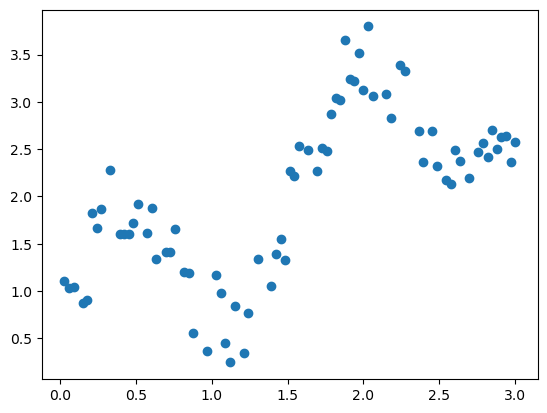

In [3]:
plt.scatter(X_train, y_train)
plt.show()

### So clearly, this is polynomial regression

Desipte that, try to implement linear regression on these datapoints and evaluate its performance

In [5]:
LinModel = LinearRegression()
LinModel.fit(X_train, y_train)

LinearRegression()

In [7]:
y_pred = LinModel.predict(X_test)

print("R2 factor:", LinModel.score(X_test, y_test))
print("MSE:", mean_squared_error(y_pred, y_test))

R2 factor: 0.41067297381418255
MSE: 0.7043403658672862


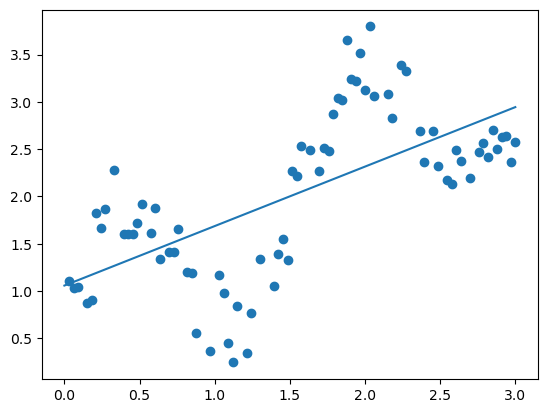

In [8]:
X_min = LinModel.coef_[0] * X.min() + LinModel.intercept_
X_max = LinModel.coef_[0] * X.max() + LinModel.intercept_

plt.scatter(X_train, y_train)
plt.plot([X.min(), X.max()], [X_min, X_max])

As you can conclude from the graph and the R2 factor, the model is not performing very well.

An R2 factor of 41% is under the acceptable threshold, which makes this model unusable. Though it's not the model's fault: it is forced to fit a straight line into a polynomial relationship. It therefore can't implement the pattern of the datapoints.

### Creating a polynomial regression model

Let's instead make a model that can actually fit the datapoints! Let's make a polynomial regression model!

In [12]:
PolyModel = LinearRegression()
PolyFactor = PolynomialFeatures(degree=0)

Tran_X_Train = PolyFactor.fit_transform(X_train)
Tran_X_Test = PolyFactor.fit_transform(X_test)

PolyModel.fit(Tran_X_Train, y_train)

LinearRegression()

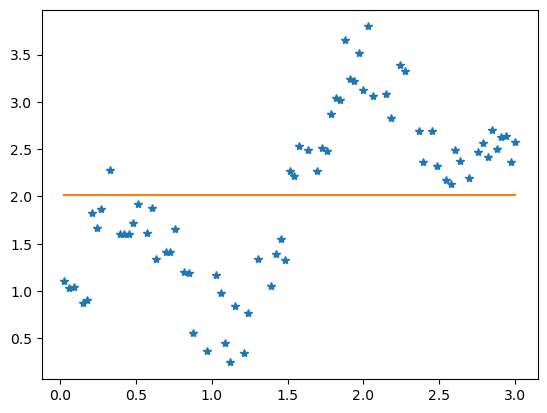

In [14]:
x = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1, 1)
plt.plot(X_train, y_train, "*")
plt.plot(x, PolyModel.predict(PolyFactor.fit_transform(x)))
plt.show()

The R2 score of this model on the train set is: 0.8555374678146463


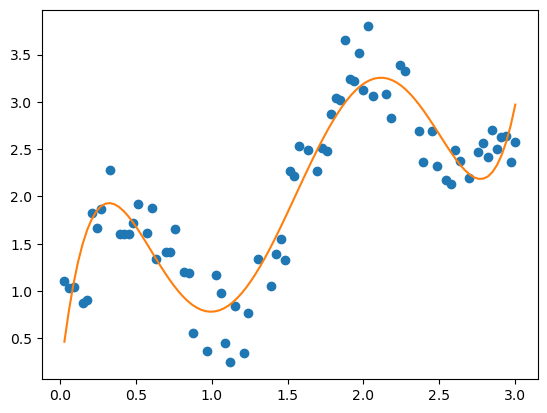

In [19]:
def poly_test(x):
    pol_exp = PolynomialFeatures(degree=x) # degree => Has a direct impact on the polynomial regression. It determines the amount of factors in the equation. Aka, the amount of times the line of best fit is allowed to bend.
    model = LinearRegression()
    model.fit(pol_exp.fit_transform(X_train), y_train)
    print('The R2 score of this model on the train set is:', model.score(pol_exp.fit_transform(X_train), y_train))
    x = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1,1) 
    plt.plot(X_train, y_train, 'o')
    plt.plot(x, model.predict(pol_exp.fit_transform(x))) 
    plt.show()
    
poly_test(5)    

# Exercise!

Now that we've brushed up on our polynomial regression knowledge, exercise with the auto.csv data.

In [21]:
df = pd.read_csv("Auto.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [22]:
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower        int64
weight            int64
acceleration    float64
model year        int64
origin            int64
car name         object
dtype: object

In [33]:
print(len(df["car name"].unique()))
print(len(df["car name"]))

305
398


In [34]:
df = df.drop("car name", axis=1)

In [ ]:
df = pd.get_dummies(df, columns=["origin"])

<Axes: >

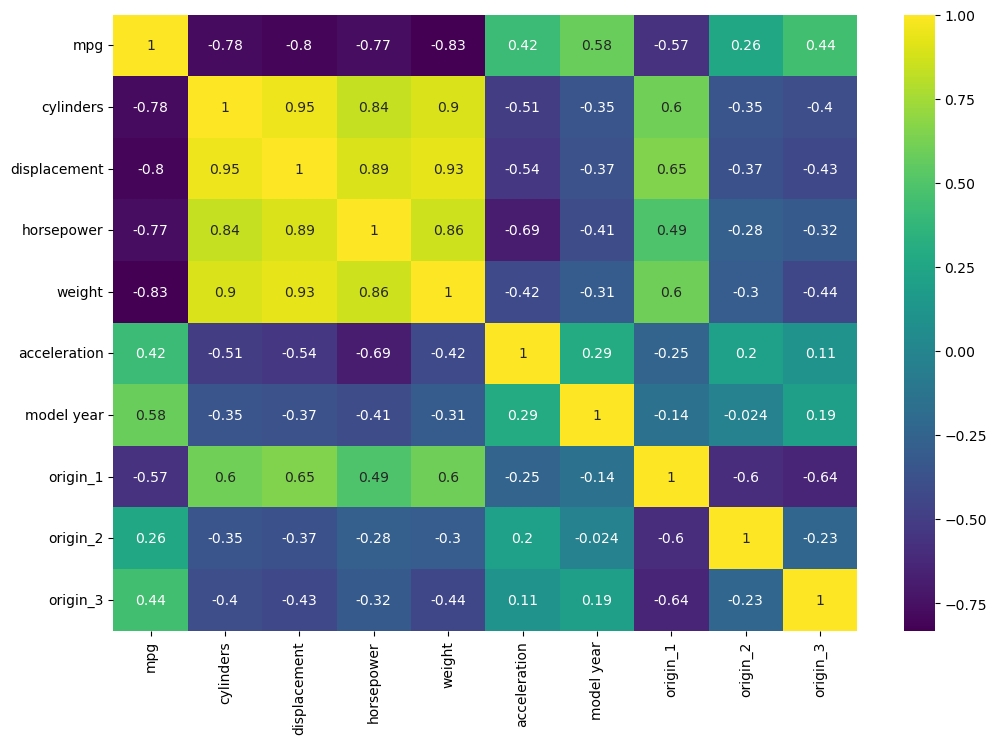

In [41]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), cmap="viridis",annot=True)

MPG => Cylinders, Displacement, Horsepower, Weight (Negative correlation)
MPG => model_year (positive correlation)

### Can you do it again? Do it agaaaiin, do it aaaggaaaiiinn, do it agaaiiinn

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

import seaborn as sns
import matplotlib.pyplot as plt

In [14]:
df = pd.read_csv("Auto.csv")
df = df.drop("car name", axis=1)
dummies = pd.get_dummies(df["origin"], dtype=int)
df = df.drop("origin", axis=1)
df = pd.concat([df, dummies], axis=1)
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,1,2,3
0,18.0,8,307.0,130,3504,12.0,70,1,0,0
1,15.0,8,350.0,165,3693,11.5,70,1,0,0
2,18.0,8,318.0,150,3436,11.0,70,1,0,0
3,16.0,8,304.0,150,3433,12.0,70,1,0,0
4,17.0,8,302.0,140,3449,10.5,70,1,0,0
...,...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1,0,0
394,44.0,4,97.0,52,2130,24.6,82,0,1,0
395,32.0,4,135.0,84,2295,11.6,82,1,0,0
396,28.0,4,120.0,79,2625,18.6,82,1,0,0


<Axes: >

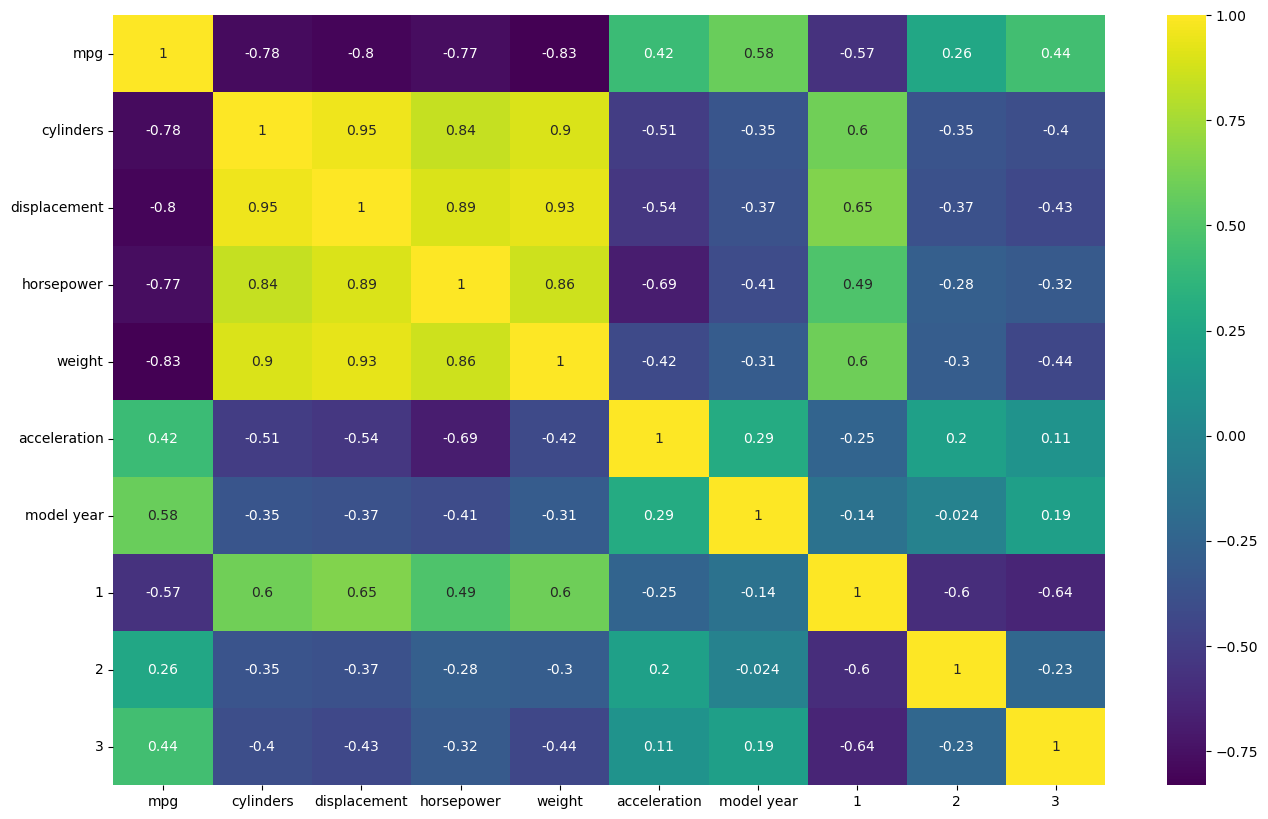

In [16]:
plt.figure(figsize=(16,10))

sns.heatmap(df.corr(), annot=True, cmap="viridis")

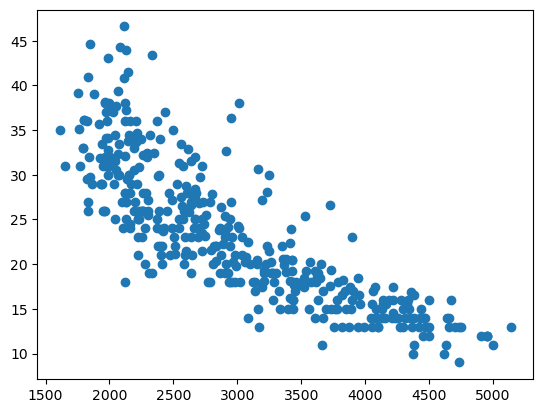

In [18]:
plt.scatter(df["weight"], df["mpg"])

In [28]:
X = df[["weight"]]
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

polyfeatures = PolynomialFeatures(degree=5)
model = LinearRegression()

TRx = polyfeatures.fit_transform(X_train)
TEx = polyfeatures.transform(X_test)

model.fit(TRx, y_train)

LinearRegression()

In [30]:
model.score(TEx, y_test)

0.7419823528081846